In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm
from sklearn.decomposition import PCA
from pathlib import Path
import pandas as pd

In [2]:
FASTA_GEN = Path("./results/featuredca/PF01628_topt_ave_generation/jdomain.generated.fasta")      

In [3]:
def read_fasta(path):
    """Return a list of (header without '>', sequence) in file order."""
    records, header, chunks = [], None, []
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\r\n")
            if line.startswith(">"):
                if header is not None:
                    records.append((header, "".join(chunks)))
                header, chunks = line[1:].strip(), []
            elif header is not None:
                chunks.append(line.strip())
            elif line.strip():
                raise ValueError(f"{path}: sequence data before the first '>' header")
    if header is not None:
        records.append((header, "".join(chunks)))
    return records


records = read_fasta(FASTA_GEN)
seqs = pd.DataFrame(records, columns=["header", "sequence"])

In [4]:
seqs["Topt_ave"]=[float(header.split("|")[3].split("=")[1]) for header in seqs["header"]]

PCA of 3,832 sequences (one-hot alignment, 217 columns); Spearman rho with Topt_ave: PC1 0.16, PC2 0.01


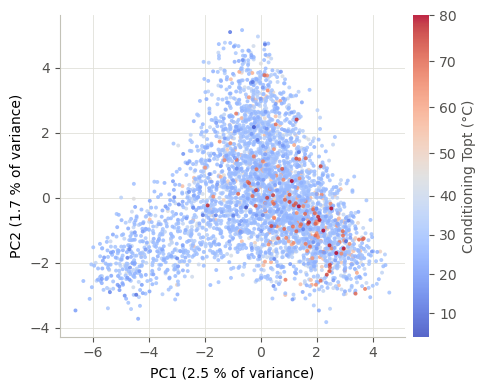

In [5]:
ALPHABET = "-ACDEFGHIKLMNPQRSTVWY"   # one-hot states; any other character (X, B, Z, ...) counts as a gap
MAX_GAP_FRACTION = 0.5     # alignment only: leave out rows with more gaps than this (fragments dominate the PCs)
MAX_FIT_SEQS = 20_000      # the PCA is fitted on a random subset of at most this many sequences ...
CHUNK = 10_000             # ... and then every sequence is projected, this many at a time
COLOR_CENTER = 45.0        # Topt (°C) at the neutral middle of the colour scale: blue below, red above
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

pca_df = seqs

# A2M/A3M: lower-case letters and '.' are insertions, not alignment columns -> drop them
cols = pca_df["sequence"].str.replace(r"[a-z.]", "", regex=True)


L, q = len(cols.iloc[0]), len(ALPHABET)
lut = np.zeros(256, dtype=np.int64)                 # unknown characters -> state 0 (gap)
for i, a in enumerate(ALPHABET):
    lut[ord(a)] = i
codes = lut[np.frombuffer("".join(cols).encode("ascii", "replace"), dtype=np.uint8)].reshape(len(cols), L)
keep_rows = (codes == 0).mean(axis=1) <= MAX_GAP_FRACTION
if (~keep_rows).any():
    print(f"left out {(~keep_rows).sum():,} sequences with more than {MAX_GAP_FRACTION:.0%} gaps")
codes, pca_df = codes[keep_rows], pca_df[keep_rows].reset_index(drop=True)

def features(rows):
    """One-hot encoding (L x 21 columns) of the given rows."""
    X = np.zeros((len(rows), L * q), dtype=np.float32)
    X[np.arange(len(rows))[:, None], np.arange(L) * q + codes[rows]] = 1
    return X

mode = f"one-hot alignment, {L} columns"

n = len(pca_df)
if n < 3:
    raise ValueError("need at least 3 retained sequences for a PCA")
rng = np.random.default_rng(0)
fit_rows = np.sort(rng.choice(n, size=min(n, MAX_FIT_SEQS), replace=False))
pca = PCA(n_components=2, svd_solver="randomized", random_state=0).fit(features(fit_rows))
pcs = np.vstack([pca.transform(features(np.arange(s, min(s + CHUNK, n)))) for s in range(0, n, CHUNK)])
pca_df["PC1"], pca_df["PC2"] = pcs[:, 0], pcs[:, 1]
var = 100 * pca.explained_variance_ratio_

rho = {pc: pca_df[pc].rank().corr(pca_df["Topt_ave"].rank()) for pc in ("PC1", "PC2")}
print(f"PCA of {n:,} sequences ({mode}); Spearman rho with Topt_ave: "
      f"PC1 {rho['PC1']:.2f}, PC2 {rho['PC2']:.2f}")

# --- plot ------------------------------------------------------------------------------------
t = pca_df["Topt_ave"].to_numpy()
vmin, vmax = t.min(), t.max()
norm = (TwoSlopeNorm(vmin=vmin, vcenter=COLOR_CENTER, vmax=vmax) if vmin < COLOR_CENTER < vmax
        else Normalize(vmin=vmin, vmax=vmax))
order = np.argsort(np.abs(t - COLOR_CENTER))      # most extreme temperatures drawn last, i.e. on top

fig, ax = plt.subplots(figsize=(5, 4))
sc = ax.scatter(pca_df["PC1"].to_numpy()[order], pca_df["PC2"].to_numpy()[order], c=t[order],
                cmap="coolwarm", norm=norm, s=8, alpha=0.85, linewidths=0, rasterized=True, zorder=2)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Conditioning Topt (°C)", color=INK_2)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=INK_2)
ax.set_xlabel(f"PC1 ({var[0]:.1f} % of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1f} % of variance)")
ax.grid(color=GRID, lw=0.6, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=INK_2)

fig.tight_layout()
#fig_path = Path(f"{stem}_tempura_pca.png")
#fig.savefig(fig_path, dpi=200, bbox_inches="tight")
#print(f"Saved {fig_path}")
plt.show()

# Comparison with natural seqs

In [6]:
FASTA_NAT = Path("./data/processed_new/uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned/uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.aligned.maxgap50.fasta")  
from matching import load_seqs, one_hot_encode
seqs_nat, ids_nat = load_seqs(FASTA_NAT, return_ID=True)
seqs_nat[seqs_nat == 'X'] = '-'

seqs_oh_nat=one_hot_encode(seqs_nat)

pca = PCA(n_components=2)
features_nat = pca.fit_transform(seqs_oh_nat)


seqs_gen, ids_gen = load_seqs(FASTA_GEN, return_ID=True)
seqs_gen[seqs_gen == 'X'] = '-'

seqs_oh_gen=one_hot_encode(seqs_gen)

features_gen = pca.transform(seqs_oh_gen)

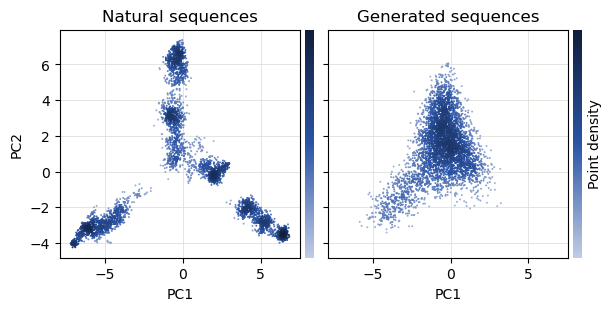

In [8]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, PowerNorm, to_rgb
from scipy.ndimage import gaussian_filter

def hue_ramp(hex_color, name):
    """Colormap in one hue: light tint -> base color -> dark shade."""
    c = np.array(to_rgb(hex_color))
    return LinearSegmentedColormap.from_list(name, [c + (1 - c) * 0.7, c, c * 0.35])

def point_density(xy, extent, bins=150, smooth=2.0):
    """Density at each point from a smoothed 2D histogram (fast even for very many points)."""
    H, xe, ye = np.histogram2d(xy[:, 0], xy[:, 1], bins=bins, range=extent, density=True)
    H = gaussian_filter(H, smooth)
    ix = np.clip(np.searchsorted(xe, xy[:, 0], side="right") - 1, 0, bins - 1)
    iy = np.clip(np.searchsorted(ye, xy[:, 1], side="right") - 1, 0, bins - 1)
    return H[ix, iy]

# Same grid and same color scale for both sets, so the shades are comparable between panels
both = np.vstack([features_nat[:, :2], features_gen[:, :2]])
extent = [[both[:, 0].min(), both[:, 0].max()], [both[:, 1].min(), both[:, 1].max()]]
d_nat = point_density(features_nat[:, :2], extent)
d_gen = point_density(features_gen[:, :2], extent)
norm = PowerNorm(gamma=0.5, vmin=0, vmax=max(d_nat.max(), d_gen.max()))

fig, axes = plt.subplots(1, 2, figsize=(6, 3), sharey=True, constrained_layout=True, sharex=True)
panels = [(features_nat, d_nat, "#2B54A6", "Natural sequences"),
          (features_gen, d_gen, "#2B54A6", "Generated sequences")]
for ax, (X, d, col, title) in zip(axes, panels):
    order = np.argsort(d)  # draw the densest points last, on top
    sc = ax.scatter(X[order, 0], X[order, 1], c=d[order], cmap=hue_ramp(col, title),
                    norm=norm, s=2, linewidths=0, rasterized=True, zorder=2)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.grid(color=GRID, lw=0.6, zorder=0)
    cb = fig.colorbar(sc, ax=ax, pad=0.02, aspect=25)
    cb.outline.set_visible(False)
    cb.set_ticks([])
axes[0].set_ylabel("PC2")
cb.set_label("Point density")
plt.show()

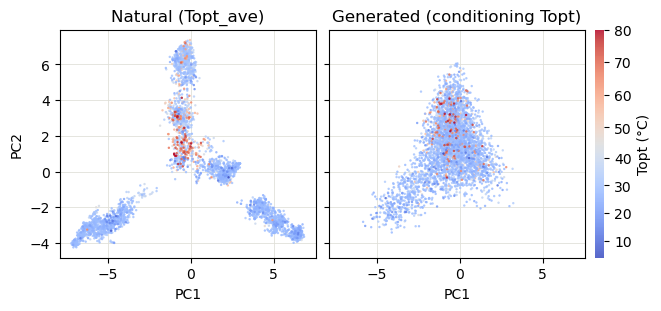

In [9]:
import re
from matplotlib.colors import Normalize, TwoSlopeNorm

TOPT_RE = re.compile(r"\bTopt_ave=([-+]?\d*\.?\d+)")

def topt_from_headers(headers):
    """Value of the 'Topt_ave=<value>' tag in each header (NaN if absent)."""
    return np.array([float(m.group(1)) if (m := TOPT_RE.search(h)) else np.nan for h in headers])

def fasta_headers(path):
    """Full header lines (without '>') in file order."""
    with open(path) as fh:
        return [line[1:].strip() for line in fh if line.startswith(">")]

# Natural: Topt_ave of the source organism (tag added by filter_fasta_by_tempura)
t_nat = topt_from_headers(ids_nat)
if np.isnan(t_nat).all():                      # load_seqs kept only the ID -> read the full headers
    t_nat = topt_from_headers(fasta_headers(FASTA_NAT))
# Generated: conditioning Topt, 4th '|' field of the header (same parsing as above)
t_gen = np.array([float(h.split("|")[3].split("=")[1]) for h in ids_gen])
assert len(t_nat) == len(features_nat) and len(t_gen) == len(features_gen), "temperatures and PCA rows don't match"
if np.isnan(t_nat).any():
    print(f"{np.isnan(t_nat).sum():,} natural sequences without Topt_ave (drawn in grey)")

# One colour scale for both panels, centred at COLOR_CENTER like the PCA plot above
vmin, vmax = np.nanmin(np.r_[t_nat, t_gen]), np.nanmax(np.r_[t_nat, t_gen])
norm_t = (TwoSlopeNorm(vmin=vmin, vcenter=COLOR_CENTER, vmax=vmax) if vmin < COLOR_CENTER < vmax
          else Normalize(vmin=vmin, vmax=vmax))

fig, axes = plt.subplots(1, 2, figsize=(6.5, 3), sharex=True, sharey=True, constrained_layout=True)
panels = [(features_nat, t_nat, "Natural (Topt_ave)"),
          (features_gen, t_gen, "Generated (conditioning Topt)")]
for ax, (X, t, title) in zip(axes, panels):
    nan = np.isnan(t)
    ax.scatter(X[nan, 0], X[nan, 1], color=AXIS, s=2, linewidths=0, rasterized=True, zorder=1)
    idx = np.flatnonzero(~nan)
    idx = idx[np.argsort(np.abs(t[idx] - COLOR_CENTER))]   # most extreme temperatures drawn last, on top
    sc = ax.scatter(X[idx, 0], X[idx, 1], c=t[idx], cmap="coolwarm", norm=norm_t,
                    s=3, alpha=0.85, linewidths=0, rasterized=True, zorder=2)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.grid(color=GRID, lw=0.6, zorder=0)
    ax.set_axisbelow(True)
axes[0].set_ylabel("PC2")
cb = fig.colorbar(sc, ax=axes, pad=0.02, aspect=25)
cb.outline.set_visible(False)
cb.set_label("Topt (°C)")
plt.show()


# Distance from consensus sequence vs temperature

In [10]:
consensus_seq = np.zeros(len(seqs_nat[0]), dtype='<U1')
for i in range(np.shape(seqs_nat)[1]):
    values, counts = np.unique(seqs_nat[:, i], return_counts=True)
    consensus_seq[i] = values[np.argmax(counts)]

# for each sequence in seqs, calculate the hamming distance to the consensus sequence
hdist_from_cons=[]
Topt_ave = []
for i in range(np.shape(seqs_nat)[0]):
    hamming_distance = np.sum(seqs_nat[i] != consensus_seq)/np.shape(seqs_nat)[1]
    hdist_from_cons.append(hamming_distance)
    Topt_ave.append(float(ids_gen[i].split("|")[3].split("=")[1]))


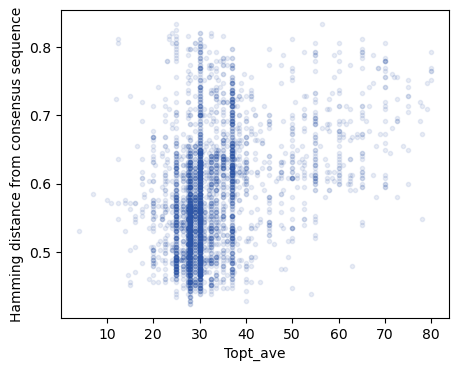

In [11]:
plt.figure(figsize=(5, 4))
plt.plot(Topt_ave, hdist_from_cons, '.', alpha=0.1, color="#2B54A6")
plt.xlabel("Topt_ave")
plt.ylabel("Hamming distance from consensus sequence")
plt.show()

# Check temp recovery

In [ ]:
pd.read_excel("./GrpE_temp_pearsons.xlsx")

AttributeError: module 'pandas' has no attribute 'read_xlsx'